In [1]:
import pandas as pd
from evaluate_on_big_family import *

In [2]:
schemes_df = pd.read_csv("data/schemes.csv")
small_fam_df = pd.read_csv("data/small_family_results.csv")
(len(schemes_df), len(small_fam_df))

(10666, 10666)

In [3]:
df = small_fam_df.join(schemes_df.set_index(list(Family._fields)), on = list(Family._fields))
len(df)

10666

In [4]:
df["score"] = df[list(Scores._fields)].sum(axis = 1)

In [5]:
df.sample(10)

,mean,std,min,quartile_1,median,quartile_3,max,father_birth,father_married,mother_birth,...,scheme,husband_wife,brother_sister,brother_brother,sister_sister,son_father,daughter_father,son_mother,daughter_mother,score
3407,0.169438,0.271309,0.0,0.00000,0.018750,0.341801,0.928125,A-B,C-D,C-D,...,Scheme3408,0.0,0.25,0.50,0.50,0.25,0.25,0.25,0.25,2.25
2917,0.226113,0.258900,0.0,0.01875,0.106751,0.424264,0.928125,A-B,A-D,C-D,...,Scheme2918,0.0,0.25,0.75,0.50,0.50,0.25,0.00,0.25,2.50
7259,0.160824,0.215583,0.0,0.00000,0.034375,0.282102,0.928125,A-B,C-A,C-D,...,Scheme7260,0.5,0.75,0.75,1.00,0.50,0.50,0.25,0.50,4.75
3364,0.175989,0.246388,0.0,0.00000,0.035155,0.282102,0.928125,A-B,C-D,C-D,...,Scheme3365,0.0,0.25,0.50,0.50,0.25,0.50,0.25,0.00,2.25
7068,0.153704,0.252716,0.0,0.00000,0.035155,0.135879,0.928125,A-B,B-D,C-D,...,Scheme7069,0.5,0.25,0.75,0.50,0.25,0.50,0.50,0.25,3.50
2428,0.145967,0.259211,0.0,0.00000,0.035155,0.106751,0.928125,A-B,C,C-D,...,Scheme2429,0.0,0.25,0.50,0.50,0.25,0.25,0.25,0.25,2.25
2405,0.182589,0.254274,0.0,0.01875,0.035155,0.347255,1.006533,A-B,C,C-D,...,Scheme2406,0.0,0.25,0.50,0.75,0.00,0.25,0.50,0.50,2.75
3324,0.236218,0.258732,0.0,0.01875,0.123744,0.424264,1.006533,A-B,C-B,C-D,...,Scheme3325,0.0,0.25,0.75,0.50,0.50,0.25,0.25,0.00,2.50
1842,0.127109,0.214123,0.0,0.00000,0.034375,0.123744,0.928125,A-B,A,C-D,...,Scheme1843,0.0,0.75,1.00,1.00,0.25,0.50,0.50,0.50,4.50
2859,0.175491,0.246159,0.0,0.00000,0.035155,0.347255,1.006533,A-B,A-D,C-D,...,Scheme2860,0.0,0.50,0.75,1.00,0.75,0.50,0.00,0.25,3.75


In [6]:
df.columns

Index(['mean', 'std', 'min', 'quartile_1', 'median', 'quartile_3', 'max',
       'father_birth', 'father_married', 'mother_birth', 'mother_married',
       'son_birth', 'daughter_birth', 'scheme', 'husband_wife',
       'brother_sister', 'brother_brother', 'sister_sister', 'son_father',
       'daughter_father', 'son_mother', 'daughter_mother', 'score'],
      dtype='str')

In [7]:
df[["score", "mean"]].corr(method="pearson")

,score,mean
score,1.000000,-0.138912
mean,-0.138912,1.000000


In [8]:
df[["score", "mean"]].corr(method="spearman")

,score,mean
score,1.000000,-0.082445
mean,-0.082445,1.000000


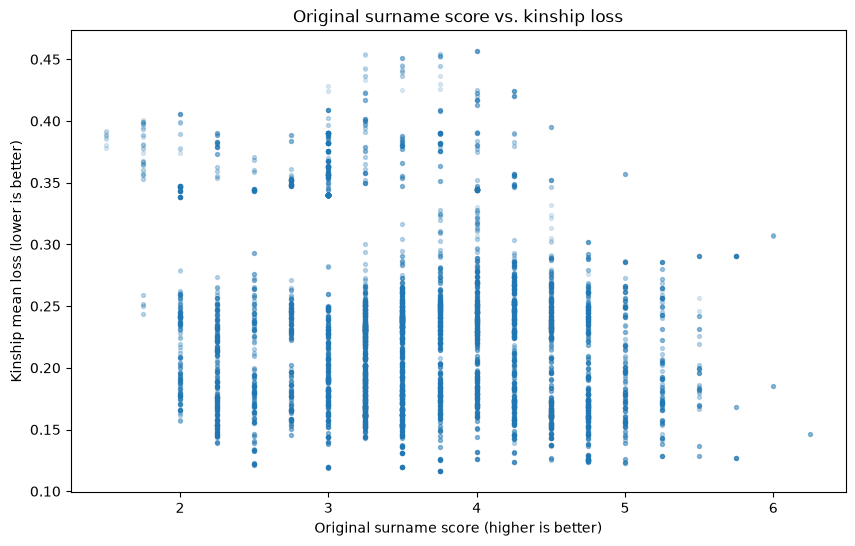

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(df["score"], df["mean"], alpha=0.15, s=8)
plt.xlabel("Original surname score (higher is better)")
plt.ylabel("Kinship mean loss (lower is better)")
plt.title("Original surname score vs. kinship loss")
plt.show()

In [10]:
from collections import Counter

counters: list[dict[float, int]] = []
num_errors: int = 0

for i in range(10):
    try:
        generate_family(50, 950)
    except NoCandidatesError:
        num_errors += 1
        continue
    path_and_similarity_scores = get_path_and_genetic_similarity_scores()
    counters.append(Counter(
        genetic_score
        for path_score, genetic_score
        in path_and_similarity_scores.values()
    ))

print(f"{num_errors = }")

generating additional people: 100%|██████████| 950/950 [00:00<00:00, 1099.07it/s]


num_errors = 0


In [11]:
for i, counter in enumerate(counters):
    print(f"{i}: {counter}")

0: Counter({0: 228722, 0.125: 100091, 0.0625: 56750, 0.25: 45855, 0.09375: 19474, 0.5: 15631, 0.1875: 9689, 0.03125: 5310, 0.15625: 4625, 1.0: 4276, 0.3125: 2972, 0.078125: 2781, 0.109375: 1489, 0.046875: 573, 0.140625: 506, 0.375: 202, 0.171875: 134, 0.296875: 133, 0.28125: 119, 0.265625: 81, 0.328125: 62, 0.203125: 18, 0.34375: 5, 0.21875: 2})
1: Counter({0: 250459, 0.125: 79368, 0.0625: 64771, 0.25: 38166, 0.09375: 18326, 0.5: 14263, 0.03125: 7532, 0.15625: 6181, 0.1875: 5184, 1.0: 4184, 0.078125: 4015, 0.109375: 2274, 0.3125: 2019, 0.046875: 1435, 0.140625: 341, 0.28125: 336, 0.375: 180, 0.265625: 158, 0.296875: 120, 0.328125: 56, 0.171875: 49, 0.34375: 45, 0.203125: 30, 0.015625: 8})
2: Counter({0: 291486, 0.125: 61281, 0.0625: 59001, 0.25: 33569, 0.5: 13584, 0.03125: 13337, 0.09375: 7851, 0.15625: 4976, 1.0: 4107, 0.046875: 2420, 0.1875: 1920, 0.078125: 1920, 0.109375: 1576, 0.3125: 906, 0.140625: 681, 0.265625: 302, 0.28125: 240, 0.015625: 106, 0.328125: 87, 0.171875: 78, 0.375:

In [12]:
metadata = generate_family(50, 950)

grandchild = next(
    p for p in PEOPLE.values()
    if metadata.person_to_gen[p] >= 2
)

parent = grandchild.parents[0]
grandparent = parent.parents[0]

print("Grandchild:", grandchild.name)
print("Parent:", parent.name)
print("Grandparent:", grandparent.name)

print("Parent-child A:", relatedness(parent, grandchild))
print("Grandparent-grandchild A:", relatedness(grandparent, grandchild))
print("Grandparent-grandchild G:", 2 * relatedness(grandparent, grandchild))

generating additional people: 100%|██████████| 950/950 [00:01<00:00, 721.85it/s] 

Grandchild: mlfunoeqco
Parent: alvubpyvtl
Grandparent: gsnlqtqveq
Parent-child A: 0.5
Grandparent-grandchild A: 0.25
Grandparent-grandchild G: 0.5


In [13]:
big_fam_df = pd.read_csv("data/big_family_results_6.csv")
big_fam_df

,mean,std,min,quartile_1,median,quartile_3,max,father_birth,father_married,mother_birth,mother_married,son_birth,daughter_birth
0,0.071705,0.106592,0.0,0.017889,0.028125,0.051320,0.517609,A,A,B,A,A,A
1,0.070094,0.105059,0.0,0.017889,0.028125,0.048643,0.517609,A,B,B,B,B,B
2,0.071705,0.106592,0.0,0.017889,0.028125,0.051320,0.517609,A-B,A-B,C-D,A-B,A-B,A-B
3,0.046376,0.044355,0.0,0.017889,0.028125,0.072157,0.517609,A-B,A-C,C-D,A-C,A-C,A-C
4,0.041915,0.044426,0.0,0.017889,0.028125,0.051320,0.517609,A-B,A-D,C-D,A-D,A-D,A-D
5,0.040196,0.037740,0.0,0.017889,0.028125,0.051320,0.517609,A-B,B-C,C-D,B-C,B-C,B-C
6,0.045395,0.042924,0.0,0.017889,0.028125,0.072157,0.517609,A-B,B-D,C-D,B-D,B-D,B-D
7,0.045395,0.042924,0.0,0.017889,0.028125,0.072157,0.517609,A-B,C-A,C-D,C-A,C-A,C-A
8,0.041915,0.044426,0.0,0.017889,0.028125,0.051320,0.517609,A-B,C-B,C-D,C-B,C-B,C-B
9,0.070094,0.105059,0.0,0.017889,0.028125,0.048643,0.517609,A-B,C-D,C-D,C-D,C-D,C-D


In [14]:
family = import_family_from_dataframe_row_index(big_fam_df, 5)
print(family)
print(family.gender_swap())

Family(father_birth='A-B', father_married='B-C', mother_birth='C-D', mother_married='B-C', son_birth='B-C', daughter_birth='B-C')
Family(father_birth='A-B', father_married='D-A', mother_birth='C-D', mother_married='D-A', son_birth='D-A', daughter_birth='D-A')


In [15]:
from itertools import combinations
from tqdm.auto import tqdm as auto_tqdm

BC_scheme = import_scheme_from_family(family)
DA_scheme = import_scheme_from_family(family.gender_swap())
metadata = generate_family(50, 950)
scores: dict[tuple[Person, Person], list[float]] = defaultdict(list)

add_surnames(BC_scheme, metadata.events, metadata.used_components)
for p1, p2 in auto_tqdm(combinations(PEOPLE.values(), 2), "B-C"):
    scores[p1, p2].append(calculate_surname_score(p1, p2))

add_surnames(DA_scheme, metadata.events, metadata.used_components)
for p1, p2 in auto_tqdm(combinations(PEOPLE.values(), 2), "D-A"):
    scores[p1, p2].append(calculate_surname_score(p1, p2))

same_count: int = sum(bc_score == da_score for bc_score, da_score in scores.values())
different_count: int = len(scores) - same_count

(same_count, different_count)

generating additional people: 100%|██████████| 950/950 [00:00<00:00, 999.57it/s] 


B-C: 0it [00:00, ?it/s]

D-A: 0it [00:00, ?it/s]

(499500, 0)

In [16]:
big_fam_df = pd.read_csv("data/big_family_results_5.csv")
df = big_fam_df.join(schemes_df.set_index(list(Family._fields)), on = list(Family._fields))
df["score"] = df[list(Scores._fields)].sum(axis = 1)

len(df)

624

In [17]:
df.nunique()

mean               244
std                244
min                  1
quartile_1           1
median               1
quartile_3          17
max                  7
father_birth         2
father_married      14
mother_birth         4
mother_married      16
son_birth           15
daughter_birth      15
scheme             624
husband_wife         3
brother_sister       4
brother_brother      3
sister_sister        3
son_father           5
daughter_father      5
son_mother           5
daughter_mother      5
score                6
dtype: int64

In [18]:
pd.concat([df[["score", "mean"]].corr(method) for method in ["pearson", "spearman"]]) # type: ignore

,score,mean
score,1.000000,0.130853
mean,0.130853,1.000000
score,1.000000,0.071918
mean,0.071918,1.000000


In [19]:
df.score.value_counts()

score
5.00    306
5.25    208
5.50     74
5.75     24
6.00      8
6.25      4
Name: count, dtype: int64

In [20]:
df.groupby("score")["mean"].agg(
    ["count", "min", "median", "max"]
).sort_index(ascending=False)

,count,min,median,max
score,,,,
6.25,4,0.045246,0.046086,0.046926
6.00,8,0.040067,0.054603,0.071314
5.75,24,0.040440,0.052777,0.062620
5.50,74,0.040735,0.050161,0.062807
5.25,208,0.041017,0.048435,0.066746
5.00,306,0.040926,0.048937,0.066112


In [21]:
df.nsmallest(10, "mean")[
    ["scheme", "score", "mean", *Family._fields]
]

,scheme,score,mean,father_birth,father_married,mother_birth,mother_married,son_birth,daughter_birth
444,Scheme6503,6.00,0.040067,A-B,B-C,C-D,B-C,B-C,B-C
579,Scheme9167,6.00,0.040067,A-B,D-A,C-D,D-A,D-A,D-A
416,Scheme5995,5.75,0.040440,A-B,B-C,C-D,C-D,B-C,B-C
557,Scheme8915,5.75,0.040440,A-B,D-A,C-D,C-D,D-A,D-A
185,Scheme4047,5.75,0.040444,A-B,A-B,C-D,D-A,D-A,D-A
232,Scheme4188,5.75,0.040444,A-B,A-B,C-D,B-C,B-C,B-C
433,Scheme6071,5.50,0.040735,A-B,B-C,C-D,D-C,B-C,B-C
569,Scheme9131,5.50,0.040735,A-B,D-A,C-D,D-C,D-A,D-A
357,Scheme5806,5.50,0.040743,A-B,B-A,C-D,D-A,D-A,D-A
394,Scheme5926,5.50,0.040743,A-B,B-A,C-D,B-C,B-C,B-C


In [22]:
best_scores = df.sort_values("mean").reset_index(drop = True)
best_scores = best_scores[best_scores.score == max(best_scores.score)]

best_scores

,mean,std,min,quartile_1,median,quartile_3,max,father_birth,father_married,mother_birth,...,scheme,husband_wife,brother_sister,brother_brother,sister_sister,son_father,daughter_father,son_mother,daughter_mother,score
140,0.045246,0.042574,0.0,0.017889,0.028125,0.072157,0.517609,A-B,D-B,C-D,...,Scheme9787,1.0,0.75,0.75,0.75,0.75,0.75,0.75,0.75,6.25
141,0.045246,0.042574,0.0,0.017889,0.028125,0.072157,0.517609,A-B,A-C,C-D,...,Scheme4535,1.0,0.75,0.75,0.75,0.75,0.75,0.75,0.75,6.25
218,0.046926,0.044182,0.0,0.017889,0.028125,0.073566,0.517609,A-B,C-A,C-D,...,Scheme7199,1.0,0.75,0.75,0.75,0.75,0.75,0.75,0.75,6.25
219,0.046926,0.044182,0.0,0.017889,0.028125,0.073566,0.517609,A-B,B-D,C-D,...,Scheme7123,1.0,0.75,0.75,0.75,0.75,0.75,0.75,0.75,6.25
